# Developing and Evaluating Transformer-Based Cyberbullying Detection Models for South African Multilingual Social Media Text Using Explainable AI

Honours research project, Sol Plaatje University.

This notebook contains the full pipeline of the study, in the order of Chapter 3 of the report:

| Model | How it is built |
|---|---|
| **AfroXLMR Baseline** | `Davlan/afro-xlmr-base` fine-tuned on English cyberbullying data |
| **AfroXLMR Adapted** | Domain-adaptive pretraining on SAfriSenti, then the same English fine-tuning |
| **AfroXLMR SA** | `Davlan/afro-xlmr-base` fine-tuned on South African (isiZulu and isiXhosa) data from AfriHate |

All three models are evaluated on the same South African test set of 610 records, and LIME and SHAP are used to explain the predictions.

The notebook was run on Google Colab with a Tesla T4 GPU. All files are read from and saved to `/content/drive/MyDrive/Honours/`. The outputs shown below each cell are the outputs of the runs that produced the results in the report.


## 1. Setup

In [ ]:
from google.colab import drive
import torch

drive.mount('/content/drive')
base = '/content/drive/MyDrive/Honours'

print("GPU Available:", torch.cuda.is_available())
print("GPU Name:", torch.cuda.get_device_name(0))


Mounted at /content/drive
GPU Available: True
GPU Name: Tesla T4


## 2. English cyberbullying data (Kaggle Cyberbullying Tweets)

In [ ]:
# Install required libraries
!pip install transformers datasets scikit-learn torch -q

import pandas as pd

# Load the cleaned English data
base = '/content/drive/MyDrive/Honours'
df = pd.read_csv(f'{base}/english_cyberbullying_clean.csv')

print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nLabel distribution:\n{df['label'].value_counts()}")
print(f"\nSample:\n{df.head()}")


Shape: (39251, 2)

Columns: ['text', 'label']

Label distribution:
label
1    31775
0     7476
Name: count, dtype: int64

Sample:
                                                text  label
0  In other words #katandandre, your food was cra...      0
1  Why is #aussietv so white? #MKR #theblock #ImA...      0
2  @XochitlSuckkks a classy whore? Or more red ve...      0
3  @Jason_Gio meh. :P  thanks for the heads up, b...      0
4  @RudhoeEnglish This is an ISIS account pretend...      0


In [ ]:
from sklearn.utils import resample

# Separate classes
df_majority = df[df['label'] == 1]
df_minority = df[df['label'] == 0]

# Downsample majority class to match minority
df_majority_downsampled = resample(
    df_majority,
    replace=False,
    n_samples=len(df_minority),
    random_state=42
)

# Combine
df_balanced = pd.concat([df_majority_downsampled, df_minority])
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Balanced dataset shape: {df_balanced.shape}")
print(f"\nNew label distribution:")
print(df_balanced['label'].value_counts())


Balanced dataset shape: (14952, 2)

New label distribution:
label
0    7476
1    7476
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# 80% train, 10% validation, 10% test
train_df, temp_df = train_test_split(
    df_balanced, test_size=0.2, random_state=42, stratify=df_balanced['label']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df['label']
)

print(f"Train: {len(train_df)} rows")
print(f"Validation: {len(val_df)} rows")
print(f"Test: {len(test_df)} rows")

# Verify balance is maintained
print(f"\nTrain label distribution:\n{train_df['label'].value_counts()}")
print(f"\nValidation label distribution:\n{val_df['label'].value_counts()}")
print(f"\nTest label distribution:\n{test_df['label'].value_counts()}")


Train: 11961 rows
Validation: 1495 rows
Test: 1496 rows

Train label distribution:
label
1    5981
0    5980
Name: count, dtype: int64

Validation label distribution:
label
0    748
1    747
Name: count, dtype: int64

Test label distribution:
label
1    748
0    748
Name: count, dtype: int64


### 2.1 Exploratory analysis of the English data
Text length by class, most frequent words by class, and the class distribution chart (Figure 8).

In [ ]:
# ─────────────────────────────────────────
# Exploratory Data Analysis (EDA)
# English Cyberbullying Dataset
# ─────────────────────────────────────────

!pip install nltk -q

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import re
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

base = '/content/drive/MyDrive/Honours'
df = pd.read_csv(f'{base}/english_cyberbullying_clean.csv')

stop_words = set(stopwords.words('english'))

# ─────────────────────────────────────────
# 1. Text length distribution by class
# ─────────────────────────────────────────
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

print("Text Length Statistics by Class:\n")
print(df.groupby('label')['word_count'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df[df['label']==0]['word_count'], bins=25, color='steelblue', edgecolor='black', alpha=0.8)
axes[0].set_title('Text Length — Not Cyberbullying')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Frequency')

axes[1].hist(df[df['label']==1]['word_count'], bins=25, color='firebrick', edgecolor='black', alpha=0.8)
axes[1].set_title('Text Length — Cyberbullying')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')

plt.suptitle('Text Length Distribution by Class', fontsize=14)
plt.tight_layout()
plt.savefig(f'{base}/eda_text_length_by_class.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nText length by class chart saved to Drive.")

# ─────────────────────────────────────────
# 2. Most common words per class
# ─────────────────────────────────────────
def get_top_words(texts, n=15):
    all_words = []
    for text in texts:
        words = re.findall(r'\b[a-zA-Z]+\b', str(text).lower())
        words = [w for w in words if w not in stop_words and w != 'user' and len(w) > 2]
        all_words.extend(words)
    return Counter(all_words).most_common(n)

top_not_bullying = get_top_words(df[df['label']==0]['text'])
top_bullying     = get_top_words(df[df['label']==1]['text'])

print("\nTop 15 words — Not Cyberbullying:")
for word, count in top_not_bullying:
    print(f"  {word}: {count}")

print("\nTop 15 words — Cyberbullying:")
for word, count in top_bullying:
    print(f"  {word}: {count}")

# ─────────────────────────────────────────
# 3. Plot most common words per class
# ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

words0, counts0 = zip(*top_not_bullying)
axes[0].barh(words0[::-1], counts0[::-1], color='steelblue')
axes[0].set_title('Most Common Words — Not Cyberbullying')
axes[0].set_xlabel('Frequency')

words1, counts1 = zip(*top_bullying)
axes[1].barh(words1[::-1], counts1[::-1], color='firebrick')
axes[1].set_title('Most Common Words — Cyberbullying')
axes[1].set_xlabel('Frequency')

plt.suptitle('Most Frequent Words by Class', fontsize=14)
plt.tight_layout()
plt.savefig(f'{base}/eda_top_words_by_class.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nTop words chart saved to Drive.")

# ─────────────────────────────────────────
# 4. Class distribution chart
# ─────────────────────────────────────────
plt.figure(figsize=(6, 5))
class_counts = df['label'].value_counts().sort_index()
bars = plt.bar(['Not Cyberbullying', 'Cyberbullying'], class_counts.values, color=['steelblue', 'firebrick'])
plt.title('Class Distribution — English Cyberbullying Dataset')
plt.ylabel('Number of Records')

for bar in bars:
    plt.annotate(
        f'{int(bar.get_height())}',
        xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
        xytext=(0, 3), textcoords="offset points",
        ha='center', fontsize=11
    )

plt.tight_layout()
plt.savefig(f'{base}/eda_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nClass distribution chart saved to Drive.")


## 3. SAfriSenti corpus
Section 3.8: record length per language (Table 6) and code-switching rates with English (Table 7, Figure 9).

In [ ]:
import pandas as pd

base = '/content/drive/MyDrive/Honours'
sa_df = pd.read_csv(f'{base}/safrisenti_evaluation.csv')
print(f"SAfriSenti records: {len(sa_df)}")
print(sa_df['language'].value_counts())

# Record length in words per language (Table 6)
sa_df['word_count'] = sa_df['text'].apply(lambda t: len(str(t).split()))
print("\nRecord length in words by language:")
print(sa_df.groupby('language')['word_count'].describe()[['mean', 'std', 'min', 'max']].round(2))


In [ ]:
# Code-switching with English (Table 7)
# A record counts as code-switched if it contains at least two English words of three or more
# letters (from the 10,000 most frequent English words in wordfreq) and at least one non-English word.
# cs_2plus is the rate reported in the study; cs_1plus uses a threshold of one English word.
!pip -q install wordfreq
import pandas as pd, re
from wordfreq import top_n_list

H2 = "/content/drive/MyDrive/Honours2/"
EN = {w for w in top_n_list("en", 10000) if len(w) >= 3 and w.isalpha()}
SKIP = {"user", "username", "url"}

def is_cs(text, min_en=2):
    toks = [w for w in re.findall(r"[a-z]+", str(text).lower()) if w not in SKIP]
    n_en = sum(w in EN for w in toks)
    return n_en >= min_en and len(toks) - n_en >= 1

files = {"Sepedi":   (H2 + "unlabelled_sepedi_tweets.csv",  ",", "tweets"),
         "Sesotho":  (H2 + "unlabelled_sesotho_tweets.csv", ",", "sentence"),
         "Setswana": (H2 + "unlabelled_setswana_tweets.csv", ",", "sentence"),
         "isiXhosa": (H2 + "xhosa_tweets.csv",              ";", "Clean_tweets"),
         "isiZulu":  (H2 + "zulu_tweets.csv",               ",", "text")}
saf = []
for lang, (path, sep, col) in files.items():
    d = pd.read_csv(path, sep=sep, encoding_errors="replace", on_bad_lines="skip")
    saf.append(pd.DataFrame({"language": lang, "text": d[col].dropna().astype(str)}))
saf = pd.concat(saf, ignore_index=True).drop_duplicates("text")

rates = saf.groupby("language").text.agg(
    n="size",
    cs_1plus=lambda s: round(100 * s.apply(is_cs, min_en=1).mean(), 1),
    cs_2plus=lambda s: round(100 * s.apply(is_cs, min_en=2).mean(), 1))
print("Code-switching with English (% of records):\n", rates.to_string())


Code-switching with English (% of records):
              n  cs_1plus  cs_2plus
language                          
Sepedi    3000      68.1      50.8
Sesotho   2998      62.8      46.3
Setswana  2999      61.0      44.5
isiXhosa  3000      62.4      45.9
isiZulu   2997      57.8      43.0


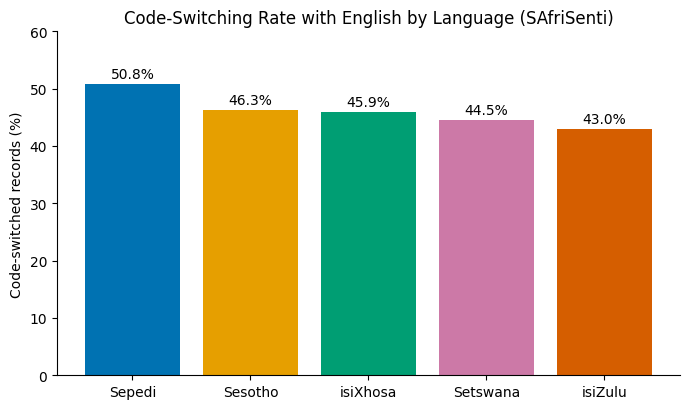

In [ ]:
# Code-switching rate per language (Figure 9), using the cs_2plus rates above
import matplotlib.pyplot as plt

langs = ["Sepedi", "Sesotho", "isiXhosa", "Setswana", "isiZulu"]
rates = [50.8, 46.3, 45.9, 44.5, 43.0]
colours = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(langs, rates, color=colours)
for b, r in zip(bars, rates):
    ax.text(b.get_x() + b.get_width() / 2, r + 1, f"{r:.1f}%", ha="center", fontsize=10)
ax.set_ylim(0, 60)
ax.set_ylabel("Code-switched records (%)")
ax.set_title("Code-Switching Rate with English by Language (SAfriSenti)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Honours/fig_code_switching_v2.png", dpi=300)
plt.show()


## 4. Domain-adaptive pretraining (for AfroXLMR Adapted)
Section 3.10.2. Training loss 3.3706 and validation loss 3.1604 after one epoch (Table 10).

In [ ]:
# Section 3.10.2: Domain-adaptive pretraining (DAPT) of AfroXLMR on SAfriSenti
# Masked language modelling, 15% masking, one epoch, learning rate 5e-5.
# 10% of the corpus is held out to report the validation loss.
# The adapted model is saved to afroxlmr_dapt. DAPT only runs if that model does not exist yet.
!pip install transformers datasets accelerate scikit-learn -q

import os
import torch
import pandas as pd
from transformers import (AutoTokenizer, AutoModelForMaskedLM,
                          DataCollatorForLanguageModeling, Trainer, TrainingArguments)
from datasets import Dataset as HFDataset

base = '/content/drive/MyDrive/Honours'

def run_dapt(model_name, save_path, unlabelled_texts, epochs=1):
    print(f"\n🚀 Starting DAPT for {model_name} on SAfriSenti (epochs={epochs})...")
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForMaskedLM.from_pretrained(model_name)

    df_unlabelled = pd.DataFrame({'text': unlabelled_texts})
    dataset = HFDataset.from_pandas(df_unlabelled)

    def tokenize(examples):
        return tokenizer(
            examples['text'],
            truncation=True,
            padding='max_length',
            max_length=128,
            return_special_tokens_mask=True
        )
    tokenized_dataset = dataset.map(tokenize, batched=True, remove_columns=['text'])
    data_collator = DataCollatorForLanguageModeling(
        tokenizer=tokenizer,
        mlm=True,
        mlm_probability=0.15
    )
    split_dataset = tokenized_dataset.train_test_split(test_size=0.1, seed=42)

    training_args = TrainingArguments(
        output_dir=f'{base}/dapt_temp',
        num_train_epochs=epochs,
        learning_rate=5e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        weight_decay=0.01,
        warmup_steps=100,
        fp16=torch.cuda.is_available(),
        logging_steps=50,
        eval_strategy='epoch',
        save_strategy='epoch',
        save_total_limit=1,
        report_to='none'
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=split_dataset['train'],
        eval_dataset=split_dataset['test'],
        data_collator=data_collator
    )

    trainer.train()
    trainer.save_model(save_path)
    tokenizer.save_pretrained(save_path)
    print(f"✅ DAPT model saved to {save_path}")
    return model, tokenizer

def check_weights(path):
    return os.path.exists(f'{path}/model.safetensors') or os.path.exists(f'{path}/pytorch_model.bin')

if not check_weights(f'{base}/afroxlmr_dapt'):
    print("afroxlmr_dapt missing weights. Running DAPT...")
    sa_df = pd.read_csv(f'{base}/safrisenti_evaluation.csv')
    unlabelled_texts = sa_df['text'].tolist()
    run_dapt('Davlan/afro-xlmr-base', f'{base}/afroxlmr_dapt', unlabelled_texts, epochs=1)
else:
    print("afroxlmr_dapt found. DAPT is not run again.")


afroxlmr_dapt missing weights. Running DAPT...

🚀 Starting DAPT for Davlan/afro-xlmr-base on SAfriSenti (epochs=1)...


Epoch,Training Loss,Validation Loss
1,3.370559,3.160378


✅ DAPT model saved to /content/drive/MyDrive/Honours/afroxlmr_dapt


## English fine-tuning
Both models are fine-tuned on the same 11,961 English training records and validated on the same 1,495 records. The English test portion (1,496 records) is not used for evaluation; all models are evaluated on the South African test set in Section 7.
### AfroXLMR Baseline

In [ ]:
# 5.1 AfroXLMR Baseline: fine-tune Davlan/afro-xlmr-base on the English data
# AdamW, learning rate 2e-5, weight decay 0.01, batch size 16, 3 epochs, 100 warm-up steps.
# The checkpoint with the best validation F1 is kept.

import os
import torch
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset
import warnings
warnings.filterwarnings('ignore')

base = '/content/drive/MyDrive/Honours'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# ─────────────────────────────────────────
# 1. Load, balance and split the data (same 80/10/10 split as Section 2)
# ─────────────────────────────────────────
df = pd.read_csv(f'{base}/english_cyberbullying_clean.csv')
df_majority = df[df['label'] == 1]
df_minority = df[df['label'] == 0]
df_majority_downsampled = resample(df_majority, replace=False, n_samples=len(df_minority), random_state=42)
df_balanced = pd.concat([df_majority_downsampled, df_minority]).sample(frac=1, random_state=42).reset_index(drop=True)

train_df, temp_df = train_test_split(df_balanced, test_size=0.2, random_state=42, stratify=df_balanced['label'])
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42, stratify=temp_df['label'])
print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

# ─────────────────────────────────────────
# 2. Metrics function
# ─────────────────────────────────────────
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = logits.argmax(axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions)
    prec = precision_score(labels, predictions)
    rec = recall_score(labels, predictions)
    return {'accuracy': acc, 'f1': f1, 'precision': prec, 'recall': rec}

# ─────────────────────────────────────────
# 3. Load tokenizer and model
# ─────────────────────────────────────────
MODEL_NAME = "Davlan/afro-xlmr-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
model.to(device)

# ─────────────────────────────────────────
# 4. Tokenize datasets
# ─────────────────────────────────────────
def tokenize_function(examples):
    return tokenizer(examples['text'], padding='max_length', truncation=True, max_length=128)

train_dataset = Dataset.from_pandas(train_df[['text', 'label']])
val_dataset   = Dataset.from_pandas(val_df[['text', 'label']])

train_dataset = train_dataset.map(tokenize_function, batched=True).rename_column('label', 'labels')
val_dataset   = val_dataset.map(tokenize_function, batched=True).rename_column('label', 'labels')

# ─────────────────────────────────────────
# 5. Training arguments
# ─────────────────────────────────────────
training_args = TrainingArguments(
    output_dir='./afro_temp',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=100,
    fp16=torch.cuda.is_available(),
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    greater_is_better=True,
    logging_steps=50,
    report_to='none',
    save_total_limit=2
)

# ─────────────────────────────────────────
# 6. Trainer
# ─────────────────────────────────────────
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

# ─────────────────────────────────────────
# 7. Train and save
# ─────────────────────────────────────────
print("\n🚀 Training AfroXLMR Baseline...")
trainer.train()
print("✅ Training complete.")

# Save model
save_path = f'{base}/afroxlmr_finetuned'
trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)
print(f"\n✅ AfroXLMR Baseline saved to {save_path}")


Device: cuda
Train: 11961, Val: 1495, Test: 1496



🚀 Training AfroXLMR Baseline...


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.214751,0.246736,0.906355,0.905787,0.910690,0.900937
2,0.164455,0.273050,0.920401,0.919649,0.927793,0.911647
3,0.127467,0.282626,0.927759,0.927419,0.931174,0.923695


✅ Training complete.



✅ AfroXLMR Baseline saved to /content/drive/MyDrive/Honours/afroxlmr_finetuned


### AfroXLMR Adapted

In [ ]:
# 5.2 AfroXLMR Adapted: fine-tune the DAPT model (afroxlmr_dapt) on the same English data
# Same settings as the Baseline: AdamW, learning rate 2e-5, weight decay 0.01, batch size 16,
# 3 epochs, 100 warm-up steps, linear schedule. The epoch with the best validation F1 is kept.
import copy
import torch
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_scheduler

base = '/content/drive/MyDrive/Honours'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# ─────────────────────────────────────────
# 1. Load, balance and split the data (same 80/10/10 split as Section 2)
# ─────────────────────────────────────────
df = pd.read_csv(f'{base}/english_cyberbullying_clean.csv')
df_majority = df[df['label'] == 1]
df_minority = df[df['label'] == 0]
df_majority_downsampled = resample(df_majority, replace=False, n_samples=len(df_minority), random_state=42)
df_balanced = pd.concat([df_majority_downsampled, df_minority]).sample(frac=1, random_state=42).reset_index(drop=True)

train_df, temp_df = train_test_split(df_balanced, test_size=0.2, random_state=42, stratify=df_balanced['label'])
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42, stratify=temp_df['label'])
print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

# ─────────────────────────────────────────
# 2. Dataset and evaluation helpers
# ─────────────────────────────────────────
class CyberbullyingDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.encodings = tokenizer(list(texts), truncation=True, padding='max_length',
                                   max_length=max_length, return_tensors='pt')
        self.labels = torch.tensor(list(labels), dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return {
            'input_ids': self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels': self.labels[idx]
        }

def evaluate_model(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return {
        'accuracy': accuracy_score(all_labels, all_preds),
        'f1': f1_score(all_labels, all_preds)
    }

# ─────────────────────────────────────────
# 3. Fine-tuning loop
# ─────────────────────────────────────────
def finetune_adapted(model_path, save_name):
    print(f"\n{'='*50}\nFine-tuning ADAPTED model from: {model_path}\n{'='*50}")
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path, num_labels=2)
    model.to(device)

    train_data = CyberbullyingDataset(train_df['text'], train_df['label'], tokenizer)
    val_data   = CyberbullyingDataset(val_df['text'],   val_df['label'],   tokenizer)

    train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
    val_loader   = DataLoader(val_data,   batch_size=16)

    optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    num_training_steps = 3 * len(train_loader)
    scheduler = get_scheduler("linear", optimizer=optimizer, num_warmup_steps=100,
                              num_training_steps=num_training_steps)

    best_f1 = 0
    best_state = None

    for epoch in range(3):
        model.train()
        for i, batch in enumerate(train_loader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            loss.backward()
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            if i % 100 == 0:
                print(f"Epoch {epoch+1} | Step {i}/{len(train_loader)} | Loss: {loss.item():.4f}")

        val_metrics = evaluate_model(model, val_loader)
        print(f"Epoch {epoch+1} Val — Acc: {val_metrics['accuracy']:.4f} | F1: {val_metrics['f1']:.4f}")

        if val_metrics['f1'] > best_f1:
            best_f1 = val_metrics['f1']
            best_state = copy.deepcopy(model.state_dict())   # keep the best epoch

    model.load_state_dict(best_state)

    save_path = f'{base}/{save_name}'
    model.save_pretrained(save_path)
    tokenizer.save_pretrained(save_path)
    print(f"Saved to {save_path}")
    return model, tokenizer

print("\n🚀 Starting AfroXLMR + DAPT fine-tuning...")
afro_adapted_model, afro_adapted_tokenizer = finetune_adapted(
    f'{base}/afroxlmr_dapt', 'afroxlmr_adapted_finetuned'
)


Using device: cuda
Train: 11961, Val: 1495, Test: 1496

🚀 Starting AfroXLMR + DAPT fine-tuning...

Fine-tuning ADAPTED model from: /content/drive/MyDrive/Honours/afroxlmr_dapt


Epoch 1 | Step 0/748 | Loss: 0.7228
Epoch 1 | Step 100/748 | Loss: 0.2586
Epoch 1 | Step 200/748 | Loss: 0.2809
Epoch 1 | Step 300/748 | Loss: 0.2907
Epoch 1 | Step 400/748 | Loss: 0.0829
Epoch 1 | Step 500/748 | Loss: 0.1354
Epoch 1 | Step 600/748 | Loss: 0.1864
Epoch 1 | Step 700/748 | Loss: 0.3591
Epoch 1 Val — Acc: 0.9171 | F1: 0.9171
Epoch 2 | Step 0/748 | Loss: 0.1348
Epoch 2 | Step 100/748 | Loss: 0.0188
Epoch 2 | Step 200/748 | Loss: 0.0620
Epoch 2 | Step 300/748 | Loss: 0.1224
Epoch 2 | Step 400/748 | Loss: 0.2079
Epoch 2 | Step 500/748 | Loss: 0.2577
Epoch 2 | Step 600/748 | Loss: 0.2902
Epoch 2 | Step 700/748 | Loss: 0.1640
Epoch 2 Val — Acc: 0.9237 | F1: 0.9226
Epoch 3 | Step 0/748 | Loss: 0.0397
Epoch 3 | Step 100/748 | Loss: 0.0209
Epoch 3 | Step 200/748 | Loss: 0.1304
Epoch 3 | Step 300/748 | Loss: 0.3455
Epoch 3 | Step 400/748 | Loss: 0.0653
Epoch 3 | Step 500/748 | Loss: 0.1779
Epoch 3 | Step 600/748 | Loss: 0.0163
Epoch 3 | Step 700/748 | Loss: 0.1071
Epoch 3 Val — Ac

Saved to /content/drive/MyDrive/Honours/afroxlmr_adapted_finetuned


## South African cyberbullying dataset (AfriHate isiZulu and isiXhosa)
Section 3.9.5: clean, remove duplicates, balance and split 80/10/10, stratified by label and language. Abuse and Hate are mapped to cyberbullying (1) and Normal to not cyberbullying (0). Saves `sa_v2_train.csv`, `sa_v2_val.csv` and `sa_v2_test.csv`.

In [ ]:
!pip -q install ftfy
import pandas as pd, numpy as np, re, html, ftfy
from sklearn.model_selection import train_test_split

H = "/content/drive/MyDrive/Honours/"
frames = []
for f, lang in [("zul_all_data.tsv", "zul"), ("xho_all_data.tsv", "xho")]:
    d = pd.read_csv(H + f, sep="\t")
    d["lang"] = lang
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
print("Raw records:", len(raw), raw.label.value_counts().to_dict())

def clean(t):
    t = ftfy.fix_text(str(t))                  # repair garbled characters
    t = html.unescape(t)                       # &amp; -> &
    t = t.lower()
    t = re.sub(r"##url", " ", t)               # AfriHate URL placeholder
    t = re.sub(r"http\S+|www\.\S+", " ", t)    # any remaining URLs
    t = re.sub(r"@\w+", "@user", t)            # one mention placeholder for all
    return re.sub(r"\s+", " ", t).strip()

raw["text"] = raw["tweet"].apply(clean)
raw["y"] = raw["label"].map({"Normal": 0, "Abuse": 1, "Hate": 1})
raw = raw[raw.text.str.len() > 0]

# Drop texts that appear with conflicting labels, then exact duplicates
n_lab = raw.groupby("text")["y"].nunique()
conflicting = set(n_lab[n_lab > 1].index)
before = len(raw)
raw = raw[~raw.text.isin(conflicting)].drop_duplicates("text")
print(f"Removed {before - len(raw)} duplicate/conflicting records "
      f"({len(conflicting)} texts had conflicting labels). Remaining: {len(raw)}")
print("Class counts after dedup:", raw.y.value_counts().to_dict())
print("Hate vs Abuse within cyberbullying class:", raw[raw.y == 1].label.value_counts().to_dict())

# Balance by downsampling the larger class
n = raw.y.value_counts().min()
bal = pd.concat([raw[raw.y == c].sample(n, random_state=42) for c in [0, 1]])
bal = bal.sample(frac=1, random_state=42).reset_index(drop=True)
print(f"\nBalanced dataset: {len(bal)} records ({n} per class)")

# 80/10/10 split, stratified on label AND language; test is the true remainder
strat = bal.y.astype(str) + "_" + bal.lang
train, temp = train_test_split(bal, test_size=0.2, stratify=strat, random_state=42)
val, test = train_test_split(temp, test_size=0.5, stratify=strat[temp.index], random_state=42)

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name}: {len(d)}  classes={d.y.value_counts().sort_index().to_dict()}  "
          f"langs={d.lang.value_counts().to_dict()}")

# Leakage checks: all three must be 0
s = lambda d: set(d.text)
print("\nOverlap train-test:", len(s(train) & s(test)),
      "| train-val:", len(s(train) & s(val)), "| val-test:", len(s(val) & s(test)))

# Share of records containing a mention placeholder, per class
for name, d in [("train", train), ("test", test)]:
    m = d.text.str.contains("@user")
    print(f"{name} @user rate: neutral {m[d.y==0].mean()*100:.1f}%  cb {m[d.y==1].mean()*100:.1f}%")

# Save the three splits
cols = ["text", "y", "lang", "label"]
for name, d in [("train", train), ("val", val), ("test", test)]:
    d[cols].rename(columns={"y": "label", "label": "afrihate_label"}).to_csv(
        H + f"sa_v2_{name}.csv", index=False)
print("\nSaved sa_v2_train.csv, sa_v2_val.csv, sa_v2_test.csv")


Raw records: 8228 {'Normal': 4245, 'Abuse': 3389, 'Hate': 594}
Removed 1483 duplicate/conflicting records (109 texts had conflicting labels). Remaining: 6745
Class counts after dedup: {0: 3697, 1: 3048}
Hate vs Abuse within cyberbullying class: {'Abuse': 2618, 'Hate': 430}

Balanced dataset: 6096 records (3048 per class)
train: 4876  classes={0: 2438, 1: 2438}  langs={'xho': 2462, 'zul': 2414}
val: 610  classes={0: 305, 1: 305}  langs={'xho': 308, 'zul': 302}
test: 610  classes={0: 305, 1: 305}  langs={'xho': 308, 'zul': 302}

Overlap train-test: 0 | train-val: 0 | val-test: 0
train @user rate: neutral 46.4%  cb 50.7%
test @user rate: neutral 48.2%  cb 45.6%

Saved sa_v2_train.csv, sa_v2_val.csv, sa_v2_test.csv


### 6.1 Sample records (Table 3)

In [ ]:
import pandas as pd
H = "/content/drive/MyDrive/Honours/"
tr = pd.read_csv(H + "sa_v2_train.csv")
eng = tr.text.str.contains(r"\b(?:the|you|and|this|that|are|not|with)\b", regex=True)
pick = pd.concat([
    tr[(tr.label == 1) & (tr.lang == "zul")].sample(1, random_state=1),
    tr[(tr.label == 1) & (tr.lang == "xho")].sample(1, random_state=1),
    tr[(tr.label == 1) & eng].sample(1, random_state=1),
    tr[(tr.label == 0) & (tr.lang == "zul")].sample(1, random_state=1),
    tr[(tr.label == 0) & (tr.lang == "xho")].sample(1, random_state=1),
    tr[(tr.label == 0) & eng].sample(1, random_state=1)])
print(pick[["text", "lang", "label", "afrihate_label"]].to_string(index=False, max_colwidth=90))


                                                                                      text lang  label afrihate_label
                                                  "@user : isifebe sendoda"lil isibonepph?  zul      1          Abuse
                                    @user futsek nina, so nizotsha indodla zezi mali zethu  xho      1          Abuse
when people say "umsunu wakho", gotta say "umsunu wakho nawe umnqundu". be just as viol...  xho      1          Abuse
                                                                         bhebha uthule ...  zul      0         Normal
                                                      ayikazalwa inkazana engandenza lento  xho      0         Normal
and that i have to pay 15% of it? ngiwuthathaphi???! coming back here i owe somebody fo...  xho      0         Normal


## AfroXLMR SA training and evaluation of all three models
Saves the model to `afroxlmr_sa_v2` and the test predictions of all three models to `sa_v2_test_predictions.csv`.

In [ ]:
# Section 3.10.4: fine-tune AfroXLMR SA on the South African training set (4,876 records),
# then evaluate the Baseline, Adapted and SA models on the same test set (610 records).
import torch, numpy as np, pandas as pd
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, set_seed)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

H = "/content/drive/MyDrive/Honours/"
set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
train, val, test = [pd.read_csv(H + f"sa_v2_{s}.csv") for s in ["train", "val", "test"]]

tok = AutoTokenizer.from_pretrained("Davlan/afro-xlmr-base")
def to_ds(df):
    ds = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    return ds.map(lambda b: tok(b["text"], padding="max_length", truncation=True, max_length=128),
                  batched=True)
train_ds, val_ds, test_ds = to_ds(train), to_ds(val), to_ds(test)

def metrics(p):
    preds = p.predictions.argmax(-1)
    pr, rc, f1, _ = precision_recall_fscore_support(p.label_ids, preds, average="binary", zero_division=0)
    return {"accuracy": accuracy_score(p.label_ids, preds), "precision": pr, "recall": rc, "f1": f1}

args = TrainingArguments(
    output_dir="/content/sa_v2_ckpt", eval_strategy="epoch", save_strategy="epoch",
    learning_rate=2e-5, weight_decay=0.01, per_device_train_batch_size=16,
    per_device_eval_batch_size=32, num_train_epochs=3, warmup_steps=100,
    lr_scheduler_type="linear", load_best_model_at_end=True, metric_for_best_model="f1",
    save_total_limit=2, fp16=torch.cuda.is_available(), seed=42, report_to="none")

model = AutoModelForSequenceClassification.from_pretrained("Davlan/afro-xlmr-base", num_labels=2)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  compute_metrics=metrics)
trainer.train()

# Validation results per epoch
hist = pd.DataFrame(trainer.state.log_history)
print(hist[["epoch", "loss", "eval_accuracy", "eval_f1"]].groupby("epoch").first().round(4))

trainer.save_model(H + "afroxlmr_sa_v2")
tok.save_pretrained(H + "afroxlmr_sa_v2")

# Predictions from all three models on the South African test set
def get_probs(model_path, texts, bs=32):
    t = AutoTokenizer.from_pretrained(model_path)
    m = AutoModelForSequenceClassification.from_pretrained(model_path).to(device).eval()
    out = []
    for i in range(0, len(texts), bs):
        e = t(texts[i:i+bs], padding="max_length", truncation=True, max_length=128,
              return_tensors="pt").to(device)
        with torch.no_grad():
            out.extend(torch.softmax(m(**e).logits, -1)[:, 1].cpu().numpy())
    return np.array(out)

texts = test.text.astype(str).tolist()
res = test[["text", "label", "lang"]].copy()
for name, path in [("baseline", "afroxlmr_finetuned"), ("adapted", "afroxlmr_adapted_finetuned"),
                   ("sa", "afroxlmr_sa_v2")]:
    res[f"prob_{name}"] = get_probs(H + path, texts)
    res[f"pred_{name}"] = (res[f"prob_{name}"] >= 0.5).astype(int)
    p = res[f"pred_{name}"]
    pr, rc, f1, _ = precision_recall_fscore_support(res.label, p, average="binary", zero_division=0)
    print(f"\n{name}: acc={accuracy_score(res.label, p):.4f} P={pr:.4f} R={rc:.4f} F1={f1:.4f}")
    print(confusion_matrix(res.label, p))

res.to_csv(H + "sa_v2_test_predictions.csv", index=False)
print("\nSaved sa_v2_test_predictions.csv")


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.483508,0.762295,0.822581,0.668852,0.737794
2,0.570109,0.364986,0.842623,0.838188,0.849180,0.843648
3,0.570109,0.385706,0.863934,0.870000,0.855738,0.862810


            loss  eval_accuracy  eval_f1
epoch                                   
1.000000     NaN         0.7623   0.7378
1.639344  0.5701            NaN      NaN
2.000000     NaN         0.8426   0.8436
3.000000     NaN         0.8639   0.8628



baseline: acc=0.4803 P=0.2000 R=0.0131 F1=0.0246
[[289  16]
 [301   4]]



adapted: acc=0.4787 P=0.2593 R=0.0230 F1=0.0422
[[285  20]
 [298   7]]



sa: acc=0.8426 P=0.8773 R=0.7967 F1=0.8351
[[271  34]
 [ 62 243]]

Saved sa_v2_test_predictions.csv


## Statistical tests
accuracy with 95% Wilson confidence intervals, an exact binomial test against chance (50%), and McNemar's exact tests between the models.

In [ ]:
import numpy as np, pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix
from scipy.stats import binomtest
from statsmodels.stats.contingency_tables import mcnemar

H = "/content/drive/MyDrive/Honours/"
res = pd.read_csv(H + "sa_v2_test_predictions.csv")
M = ["baseline", "adapted", "sa"]

def report(df, tag):
    print(f"\n=== {tag}: n={len(df)}, [neutral, cb]={np.bincount(df.label, minlength=2).tolist()} ===")
    for m in M:
        p = df[f"pred_{m}"]
        pr, rc, f1, _ = precision_recall_fscore_support(df.label, p, average="binary", zero_division=0)
        k = int((p == df.label).sum())
        bt = binomtest(k, len(df), 0.5)
        ci = bt.proportion_ci(method="wilson")
        print(f"{m:9s} acc={k/len(df):.4f} 95%CI=[{ci.low:.3f},{ci.high:.3f}] p(vs 50%)={bt.pvalue:.3g} | "
              f"P={pr:.4f} R={rc:.4f} F1={f1:.4f} macroF1={f1_score(df.label, p, average='macro'):.4f} "
              f"| predicted cb={int(p.sum())}")

report(res, "ALL")

print("\n=== McNemar exact tests ===")
for a, b in [("baseline", "sa"), ("adapted", "sa"), ("baseline", "adapted")]:
    oa, ob = res[f"pred_{a}"] == res.label, res[f"pred_{b}"] == res.label
    t = [[int((oa & ob).sum()), int((oa & ~ob).sum())], [int((~oa & ob).sum()), int((~oa & ~ob).sum())]]
    print(f"{a} vs {b}: table={t}  p={mcnemar(t, exact=True).pvalue:.3g}")

print("\n=== Baseline vs Adapted ===")
print("Records with different predictions:", int((res.pred_baseline != res.pred_adapted).sum()), "/", len(res))
print("Mean |P(cb)| difference:", round(float(np.abs(res.prob_baseline - res.prob_adapted).mean()), 4))

d1 = int(((res.pred_sa == 1) & (res.pred_baseline == 0)).sum())
d2 = int(((res.pred_sa == 0) & (res.pred_baseline == 1)).sum())
print(f"\nDisagreements: SA=cb & Baseline=neutral: {d1} | opposite: {d2} | total: {d1+d2}")



=== ALL: n=610, [neutral, cb]=[305, 305] ===
baseline  acc=0.4803 95%CI=[0.441,0.520] p(vs 50%)=0.352 | P=0.2000 R=0.0131 F1=0.0246 macroF1=0.3352 | predicted cb=20
adapted   acc=0.4787 95%CI=[0.439,0.518] p(vs 50%)=0.311 | P=0.2593 R=0.0230 F1=0.0422 macroF1=0.3420 | predicted cb=27
sa        acc=0.8426 95%CI=[0.812,0.869] p(vs 50%)=5.33e-70 | P=0.8773 R=0.7967 F1=0.8351 macroF1=0.8423 | predicted cb=277

=== McNemar exact tests ===
baseline vs sa: table=[[259, 34], [255, 62]]  p=4.87e-43
adapted vs sa: table=[[257, 35], [257, 61]]  p=6.54e-43
baseline vs adapted: table=[[286, 7], [6, 311]]  p=1

=== Baseline vs Adapted ===
Records with different predictions: 13 / 610
Mean |P(cb)| difference: 0.0492

Disagreements: SA=cb & Baseline=neutral: 273 | opposite: 16 | total: 289


## Explainable AI: LIME and SHAP
20 records where AfroXLMR SA predicts cyberbullying and the Baseline does not (sampled with seed 42), 1,000 LIME perturbations per record, placeholder and punctuation tokens excluded. Saves `xai_v2_lime.csv` and `xai_v2_shap.csv`.

Disagreement pool: 273 | sampled: 20 | true cb: 16, true neutral (SA false positives): 4



===== LIME =====
ALL tokens: max|attr| baseline=0.0102, sa=0.9248, max ratio=90.3x, median per-sample ratio=115.4x
EXCLUDING artefacts/placeholders: max|attr| baseline=0.0102, sa=0.9248, max ratio=90.3x, median per-sample ratio=123.5x

===== SHAP =====
ALL tokens: max|attr| baseline=0.0185, sa=0.3905, max ratio=21.1x, median per-sample ratio=28.8x
EXCLUDING artefacts/placeholders: max|attr| baseline=0.0185, sa=0.3905, max ratio=21.1x, median per-sample ratio=28.8x

Top 15 LIME tokens for SA (positive towards cyberbullying, excluding artefacts):
               mean  count
token                     
istabane     0.9169      2
umthakathi   0.8327      1
umsunu       0.7728      1
ikaka        0.7092      1
isishwapa    0.6079      1
thembe       0.5997      1
mgodoyi      0.4323      1
iyellowbone  0.3950      1
mhlathi      0.3701      1
umnqundu     0.3485      1
ikula        0.3304      1
shlama       0.3174      2
kanyoko      0.2909      1
mshanami     0.2856      1
stabane      0.2

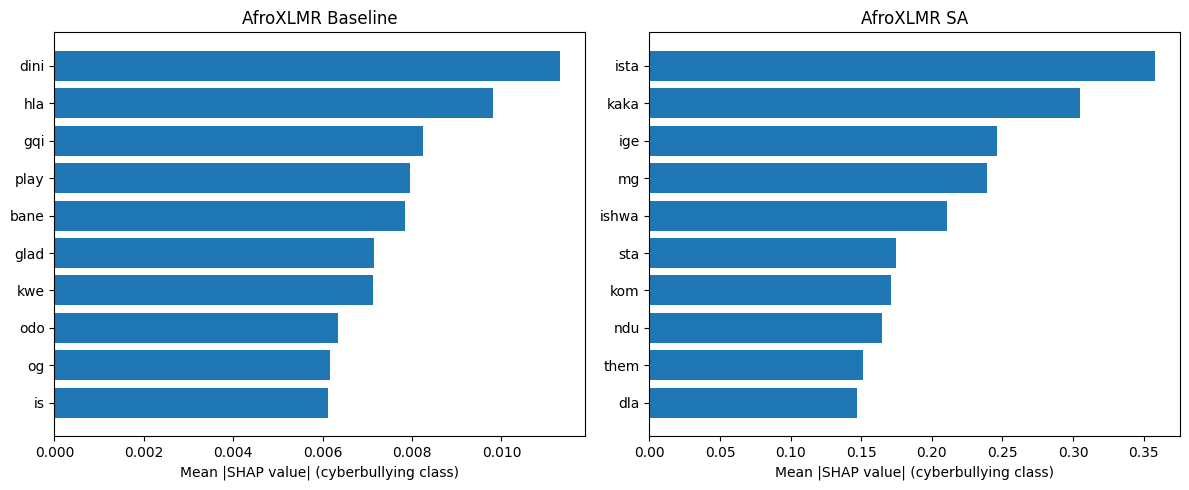


@user attribution for SA (LIME, mean weight where present): 0.0604


In [ ]:
!pip -q install lime shap
import numpy as np, pandas as pd, torch, re, shap, matplotlib.pyplot as plt
from lime.lime_text import LimeTextExplainer
from transformers import AutoTokenizer, AutoModelForSequenceClassification

H = "/content/drive/MyDrive/Honours/"
device = "cuda" if torch.cuda.is_available() else "cpu"
res = pd.read_csv(H + "sa_v2_test_predictions.csv")

def load(path):
    t = AutoTokenizer.from_pretrained(H + path)
    m = AutoModelForSequenceClassification.from_pretrained(H + path).to(device).eval()
    def f(texts, bs=64):
        texts = [str(x) for x in texts]
        out = []
        for i in range(0, len(texts), bs):
            e = t(texts[i:i+bs], padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
            with torch.no_grad():
                out.append(torch.softmax(m(**e).logits, -1).cpu().numpy())
        return np.vstack(out)
    return t, f

tok_b, f_base = load("afroxlmr_finetuned")
tok_s, f_sa   = load("afroxlmr_sa_v2")

# 20 disagreement cases (SA = cb, Baseline = neutral), sampled with seed 42
dis = res[(res.pred_sa == 1) & (res.pred_baseline == 0)]
samp = dis.sample(min(20, len(dis)), random_state=42).reset_index(drop=True)
print(f"Disagreement pool: {len(dis)} | sampled: {len(samp)} | "
      f"true cb: {int(samp.label.sum())}, true neutral (SA false positives): {int((samp.label == 0).sum())}")

ARTEFACT = re.compile(r"^(@user|@|user|▁|[^\w]+|)$")
is_art = lambda tok: bool(ARTEFACT.match(tok.strip().strip("▁").lower()))

# ---- LIME ----
lime = LimeTextExplainer(class_names=["Neutral", "Cyberbullying"], random_state=42)
rows = []
for i, r in samp.iterrows():
    for name, f in [("baseline", f_base), ("sa", f_sa)]:
        exp = lime.explain_instance(r.text, f, num_features=10, num_samples=1000, labels=(1,))
        for word, w in exp.as_list(label=1):
            rows.append({"sample": i, "model": name, "token": word, "weight": w,
                         "true_label": r.label, "artefact": is_art(word)})
lime_df = pd.DataFrame(rows)
lime_df.to_csv(H + "xai_v2_lime.csv", index=False)

# ---- SHAP ----
shap_rows = []
for name, f, t in [("baseline", f_base, tok_b), ("sa", f_sa, tok_s)]:
    expl = shap.Explainer(f, shap.maskers.Text(t), output_names=["Neutral", "Cyberbullying"])
    sv = expl(samp.text.tolist())
    for i in range(len(samp)):
        for tok_str, val in zip(sv.data[i], sv.values[i][:, 1]):
            if tok_str.strip():
                shap_rows.append({"sample": i, "model": name, "token": tok_str.strip(),
                                  "shap": float(val), "artefact": is_art(tok_str)})
shap_df = pd.DataFrame(shap_rows)
shap_df.to_csv(H + "xai_v2_shap.csv", index=False)

# ---- Summary: attribution magnitude, Baseline vs SA ----
def summarise(df, col, label):
    print(f"\n===== {label} =====")
    for subset, d in [("ALL tokens", df), ("EXCLUDING artefacts/placeholders", df[~df.artefact])]:
        mx = d.groupby("model")[col].apply(lambda s: s.abs().max())
        per = d.assign(a=d[col].abs()).groupby(["sample", "model"]).a.max().unstack()
        ratio = (per["sa"] / per["baseline"].replace(0, np.nan)).dropna()
        print(f"{subset}: max|attr| baseline={mx['baseline']:.4f}, sa={mx['sa']:.4f}, "
              f"max ratio={mx['sa']/mx['baseline']:.1f}x, median per-sample ratio={ratio.median():.1f}x")

summarise(lime_df, "weight", "LIME")
summarise(shap_df, "shap", "SHAP")

# Most influential LIME words for AfroXLMR SA
print("\nTop 15 LIME tokens for SA (positive towards cyberbullying, excluding artefacts):")
print(lime_df[(lime_df.model == "sa") & ~lime_df.artefact & (lime_df.weight > 0)]
      .groupby("token").weight.agg(["mean", "count"]).sort_values("mean", ascending=False).head(15).round(4))

# SHAP top-10 chart, excluding artefacts (Figure 14)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, title in [(axes[0], "baseline", "AfroXLMR Baseline"), (axes[1], "sa", "AfroXLMR SA")]:
    top = (shap_df[(shap_df.model == name) & ~shap_df.artefact]
           .assign(a=lambda d: d.shap.abs()).groupby("token").a.mean().nlargest(10).sort_values())
    ax.barh(top.index, top.values)
    ax.set_title(title); ax.set_xlabel("Mean |SHAP value| (cyberbullying class)")
plt.tight_layout()
plt.savefig(H + "fig_shap_v2.png", dpi=200)
plt.show()

# Attribution given to the @user placeholder by AfroXLMR SA
print("\n@user attribution for SA (LIME, mean weight where present):",
      round(lime_df[(lime_df.model == "sa") & lime_df.token.str.contains("user")].weight.mean(), 4))


### Class distribution of influential words and false positives (Table 16)

In [ ]:
import pandas as pd
H = "/content/drive/MyDrive/Honours/"
train = pd.read_csv(H + "sa_v2_train.csv")
lime_df = pd.read_csv(H + "xai_v2_lime.csv")

# 1. Class distribution of top tokens in the TRAINING data
terms = ["istabane", "stabane", "ikula", "amakula", "iyellowbone", "umthakathi", "umsunu",
         "ikaka", "mgodoyi", "umnqundu", "kanyoko", "mshanami", "thembe", "shlama", "isishwapa", "mhlathi"]
rows = []
for t in terms:
    has = train.text.str.contains(rf"\b{t}", case=False, regex=True)
    rows.append({"term": t, "train_neutral": int((has & (train.label == 0)).sum()),
                 "train_cb": int((has & (train.label == 1)).sum())})
dist = pd.DataFrame(rows)
dist["pct_cb"] = (100 * dist.train_cb / (dist.train_neutral + dist.train_cb)).round(1)
print(dist.to_string(index=False))

# 2. Most influential words in the 4 false positives
fp = lime_df[(lime_df.model == "sa") & (lime_df.true_label == 0)]
for s, g in fp.groupby("sample"):
    print(f"\nFalse positive, sample {s}:",
          g.sort_values("weight", ascending=False).head(5)[["token", "weight"]].round(3).values.tolist())


       term  train_neutral  train_cb  pct_cb
   istabane              2        52    96.3
    stabane              1        19    95.0
      ikula             15        30    66.7
    amakula              0        47   100.0
iyellowbone              1         9    90.0
 umthakathi             11        38    77.6
     umsunu              1       102    99.0
      ikaka              2       111    98.2
    mgodoyi              0        74   100.0
   umnqundu              0        90   100.0
    kanyoko             27       150    84.7
   mshanami              0         0     NaN
     thembe              0         0     NaN
     shlama              0        79   100.0
  isishwapa              0        14   100.0
    mhlathi              0        71   100.0

False positive, sample 3: [['thembe', 0.6], ['user', 0.133], ['mxxxxxm', 0.111], ['imenemene', 0.076], ['after', 0.042]]

False positive, sample 8: [['leso', 0.218], ['slima', 0.151], ['kangaka', 0.038], ['user', 0.021], ['le', -0.016

## Figures for Chapter 4
Confusion matrices (Figures 10 to 12), comparison chart (Figure 13) and the top SHAP subwords per model.

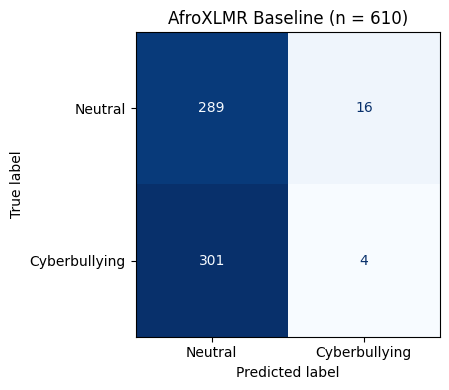

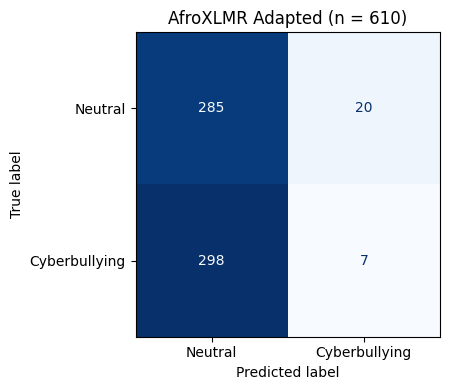

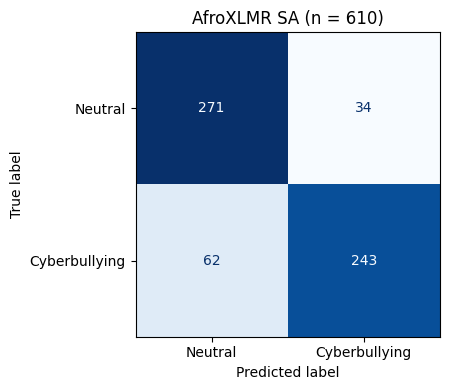

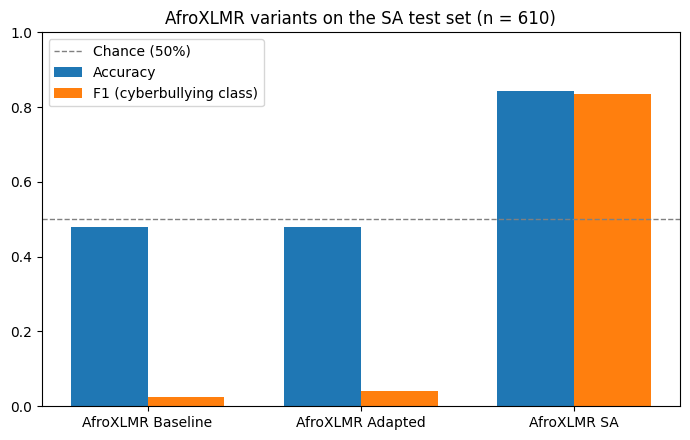


Top 10 SHAP tokens, baseline:
 token
dini    0.0113
hla     0.0098
gqi     0.0082
play    0.0080
bane    0.0078
glad    0.0071
kwe     0.0071
odo     0.0064
og      0.0062
is      0.0061

Top 10 SHAP tokens, sa:
 token
ista     0.3579
kaka     0.3051
ige      0.2464
mg       0.2388
ishwa    0.2108
sta      0.1748
kom      0.1714
ndu      0.1648
them     0.1511
dla      0.1468


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score

H = "/content/drive/MyDrive/Honours/"
res = pd.read_csv(H + "sa_v2_test_predictions.csv")
names = {"baseline": "AfroXLMR Baseline", "adapted": "AfroXLMR Adapted", "sa": "AfroXLMR SA"}

# 1. Confusion matrices (one PNG per model)
for key, title in names.items():
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(res.label, res[f"pred_{key}"],
        display_labels=["Neutral", "Cyberbullying"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{title} (n = 610)")
    plt.tight_layout(); plt.savefig(H + f"fig_cm_{key}_v2.png", dpi=200); plt.show()

# 2. Comparison chart: accuracy and F1 per model
acc = [accuracy_score(res.label, res[f"pred_{k}"]) for k in names]
f1  = [f1_score(res.label, res[f"pred_{k}"]) for k in names]
x = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - 0.18, acc, 0.36, label="Accuracy")
ax.bar(x + 0.18, f1, 0.36, label="F1 (cyberbullying class)")
ax.axhline(0.5, ls="--", c="grey", lw=1, label="Chance (50%)")
ax.set_xticks(x, names.values()); ax.set_ylim(0, 1); ax.legend()
ax.set_title("AfroXLMR variants on the SA test set (n = 610)")
plt.tight_layout(); plt.savefig(H + "fig_comparison_v2.png", dpi=200); plt.show()

# 3. Top SHAP subwords per model
shap_df = pd.read_csv(H + "xai_v2_shap.csv")
for m in ["baseline", "sa"]:
    top = (shap_df[(shap_df.model == m) & ~shap_df.artefact]
           .assign(a=lambda d: d.shap.abs()).groupby("token").a.mean().nlargest(10).round(4))
    print(f"\nTop 10 SHAP tokens, {m}:\n", top.to_string())
